In [ ]:
Healthcare Project

project: Patient Desease Risk Prediction

In [23]:
# import Libraries
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [26]:
#create HealthcareDataset (synthetic)
np.random.seed(42)
data={
    'age':np.random.randint(20,80,300),  # (start, end, howmany)
    'gender':np.random.choice(['male','female'],300),
    'bmi':np.random.uniform(18,40,300),
    'bp':np.random.randint(90,180,300),
    'glucose':np.random.randint(70,200,300),
    'cholesterol':np.random.randint(150,300,300),
    'smoking':np.random.choice(['yes','no'],300),
    'alcohol':np.random.choice(['yes','no'],300),
    'physical_activity':np.random.choice(['low','medium','high'],300),
    'disease':np.random.choice([0,1],300)
}
df=pd.DataFrame(data)
df

,age,gender,bmi,bp,glucose,cholesterol,smoking,alcohol,physical_activity,disease
0,58,male,33.311433,152,104,178,no,yes,medium,1
1,71,male,26.996965,137,132,286,yes,no,medium,0
2,48,female,21.812475,150,94,225,yes,no,high,0
3,34,male,21.441615,170,159,158,no,yes,high,1
4,62,female,23.505344,115,144,189,no,no,medium,0
...,...,...,...,...,...,...,...,...,...,...
295,25,female,18.864867,163,167,227,yes,yes,medium,1
296,41,male,35.587029,141,80,151,no,no,high,1
297,30,female,31.813809,146,174,268,yes,no,low,1
298,67,male,19.798699,115,136,186,yes,no,low,0


In [27]:
#data understanding
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df['disease'].value_counts())

(300, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                300 non-null    int32  
 1   gender             300 non-null    object 
 2   bmi                300 non-null    float64
 3   bp                 300 non-null    int32  
 4   glucose            300 non-null    int32  
 5   cholesterol        300 non-null    int32  
 6   smoking            300 non-null    object 
 7   alcohol            300 non-null    object 
 8   physical_activity  300 non-null    object 
 9   disease            300 non-null    int64  
dtypes: float64(1), int32(4), int64(1), object(4)
memory usage: 18.9+ KB
None
age                  0
gender               0
bmi                  0
bp                   0
glucose              0
cholesterol          0
smoking              0
alcohol              0
physical_activity    0
disease              0
d

Text(0.5, 1.0, 'disease Distribution')

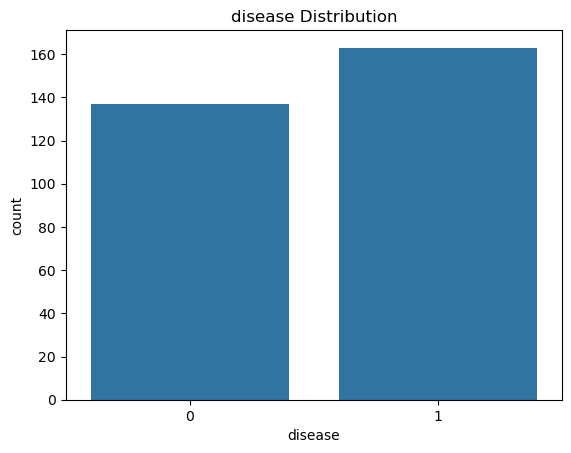

In [28]:
#Exploratory Data Analysis(EDA)
import seaborn as sns
sns.countplot(x="disease",data=df)
plt.title("disease Distribution")

<Axes: >

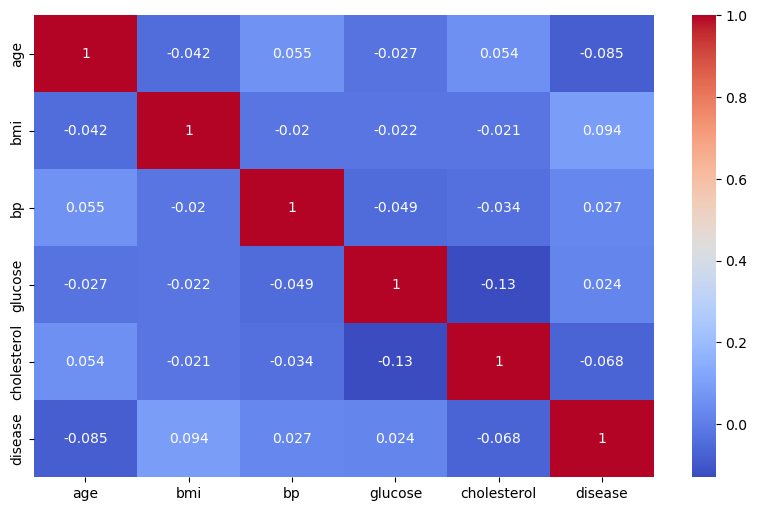

In [29]:
#correlation Heatmap
plt.figure(figsize=(10,6))
sns.heatmap(df.select_dtypes(include=np.number).corr(),annot=True,cmap='coolwarm')

In [30]:
#feature Encoding

le=LabelEncoder()
df['gender']=le.fit_transform(df['gender'])
df['smoking']=le.fit_transform(df['smoking'])
df['alcohol']=le.fit_transform(df['alcohol'])
df['physical_activity']=le.fit_transform(df['physical_activity'])

In [31]:
df

,age,gender,bmi,bp,glucose,cholesterol,smoking,alcohol,physical_activity,disease
0,58,1,33.311433,152,104,178,0,1,2,1
1,71,1,26.996965,137,132,286,1,0,2,0
2,48,0,21.812475,150,94,225,1,0,0,0
3,34,1,21.441615,170,159,158,0,1,0,1
4,62,0,23.505344,115,144,189,0,0,2,0
...,...,...,...,...,...,...,...,...,...,...
295,25,0,18.864867,163,167,227,1,1,2,1
296,41,1,35.587029,141,80,151,0,0,0,1
297,30,0,31.813809,146,174,268,1,0,1,1
298,67,1,19.798699,115,136,186,1,0,1,0


In [32]:
#feature Scaling
X=df.drop("disease",axis=1)
y=df['disease']

scaler=StandardScaler()                #he data ko same scale par lata he
X_scaled=scaler.fit_transform(X)

In [37]:
#train test split
X_train,X_test,y_train,y_test=train_test_split(X_scaled,y,test_size=0.2,random_state=42)

In [38]:
#model 1: Logistic Regression
from sklearn.metrics import accuracy_score
lr=LogisticRegression()
lr.fit(X_train,y_train)
y_pred_lr=lr.predict(X_test)
print("logistic Regression Accuracy:",accuracy_score(y_test,y_pred_lr))
print("classification Report:",classification_report(y_test,y_pred_lr))

logistic Regression Accuracy: 0.4166666666666667
classification Report:               precision    recall  f1-score   support

           0       0.29      0.28      0.29        25
           1       0.50      0.51      0.51        35

    accuracy                           0.42        60
   macro avg       0.40      0.40      0.40        60
weighted avg       0.41      0.42      0.41        60

